In [1]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np

In [4]:
data = tfds.load('oxford_iiit_pet', split='train[:300]', as_supervised=False)

def preprocess(x):
    img = tf.image.resize(x['image'], (64,64))/255.0
    mask = tf.image.resize(x['segmentation_mask'], (64,64), method='nearest')
    mask = tf.cast(mask, tf.int32)-1
    return img, mask

data = data.map(preprocess).batch(16)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling C:\Users\Lenovo\tensorflow_datasets\oxford_iiit_pet\incomplete.GWTJ1G_4.0.0\oxford_iiit_pet-train.tf…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling C:\Users\Lenovo\tensorflow_datasets\oxford_iiit_pet\incomplete.GWTJ1G_4.0.0\oxford_iiit_pet-test.tfr…

Dataset oxford_iiit_pet downloaded and prepared to C:\Users\Lenovo\tensorflow_datasets\oxford_iiit_pet\4.0.0. Subsequent calls will reuse this data.


In [5]:
from tensorflow.keras.layers import *

i = Input((64,64,3))
c1 = Conv2D(16,3,activation='relu',padding='same')(i)
p1 = MaxPooling2D()(c1)
c2 = Conv2D(32,3,activation='relu',padding='same')(p1)
u1 = UpSampling2D()(c2)
u1 = Concatenate()([u1,c1])
o = Conv2D(3,1,activation='softmax')(u1)

model = tf.keras.Model(i,o)
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [6]:
model.fit(data, epochs=3)

Epoch 1/3


C:\Users\Lenovo\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


19/19 ━━━━━━━━━━━━━━━━━━━━ 9s 68ms/step - accuracy: 0.4950 - loss: 1.0348
Epoch 2/3
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.5864 - loss: 0.9572
Epoch 3/3
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.5864 - loss: 0.9395


In [7]:
iou = tf.keras.metrics.MeanIoU(num_classes=3)

for x,y in data:
    pred = tf.argmax(model.predict(x,verbose=0),axis=-1)
    iou.update_state(y, pred)

print("IoU:", iou.result().numpy())
print("Dice:", 2*iou.result().numpy()/(1+iou.result().numpy()))
print("Pixel Accuracy:", model.evaluate(data)[1])

IoU: 0.19545329
Dice: 0.32699445
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.5864 - loss: 0.9329
Pixel Accuracy: 0.5863598585128784


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step


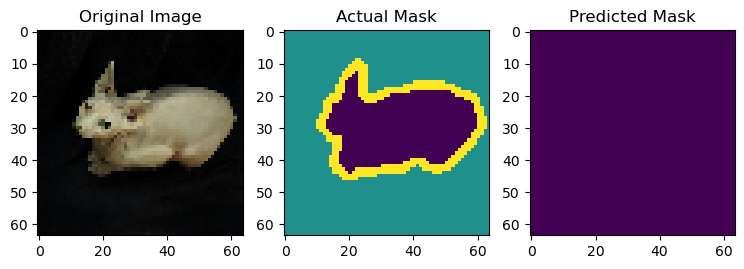

In [8]:
x,y = next(iter(data))
pred = tf.argmax(model.predict(x[:1]),axis=-1)

plt.figure(figsize=(9,3))
plt.subplot(1,3,1); plt.imshow(x[0])
plt.title("Original Image")
plt.subplot(1,3,2); plt.imshow(y[0,:,:,0])
plt.title("Actual Mask")
plt.subplot(1,3,3); plt.imshow(pred[0])
plt.title("Predicted Mask")
plt.show()